# Homework 2 — Question 3

`%pip install numpy pandas matplotlib torch scikit-learn`


### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)



### Load the provided splits

In [2]:
train = pd.read_csv("train.csv")
val = pd.read_csv("val.csv")
test = pd.read_csv("test.csv")

x_train = train[["x1", "x2"]].to_numpy()
y_train = train["y"].to_numpy()
x_val = val[["x1", "x2"]].to_numpy()
y_val = val["y"].to_numpy()
x_test = test[["x1", "x2"]].to_numpy()

print("Train / validation / test:", len(train), len(val), len(test))
print("Test columns:", list(test.columns))
print("Missing values:", int(train.isna().sum().sum()
      + val.isna().sum().sum() + test.isna().sum().sum()))



Train / validation / test: 600 200 200
Test columns: ['x1', 'x2']
Missing values: 0


## (a) Training-data visualization

I use the provided splits: **600 training points, 200 validation points, and 200 unlabeled test points**. I plot the training inputs $(x_1,x_2)$ and use color to represent $y$.

The plot shows a nonlinear relationship. Values of $y$ generally increase as $|x_2|$ becomes larger. There is also variation along $x_1$, with a low region near $x_1\approx-1.5$ and $x_2\approx0$. A linear model on the two original features would not capture this curved pattern well.


### Visualize the training data

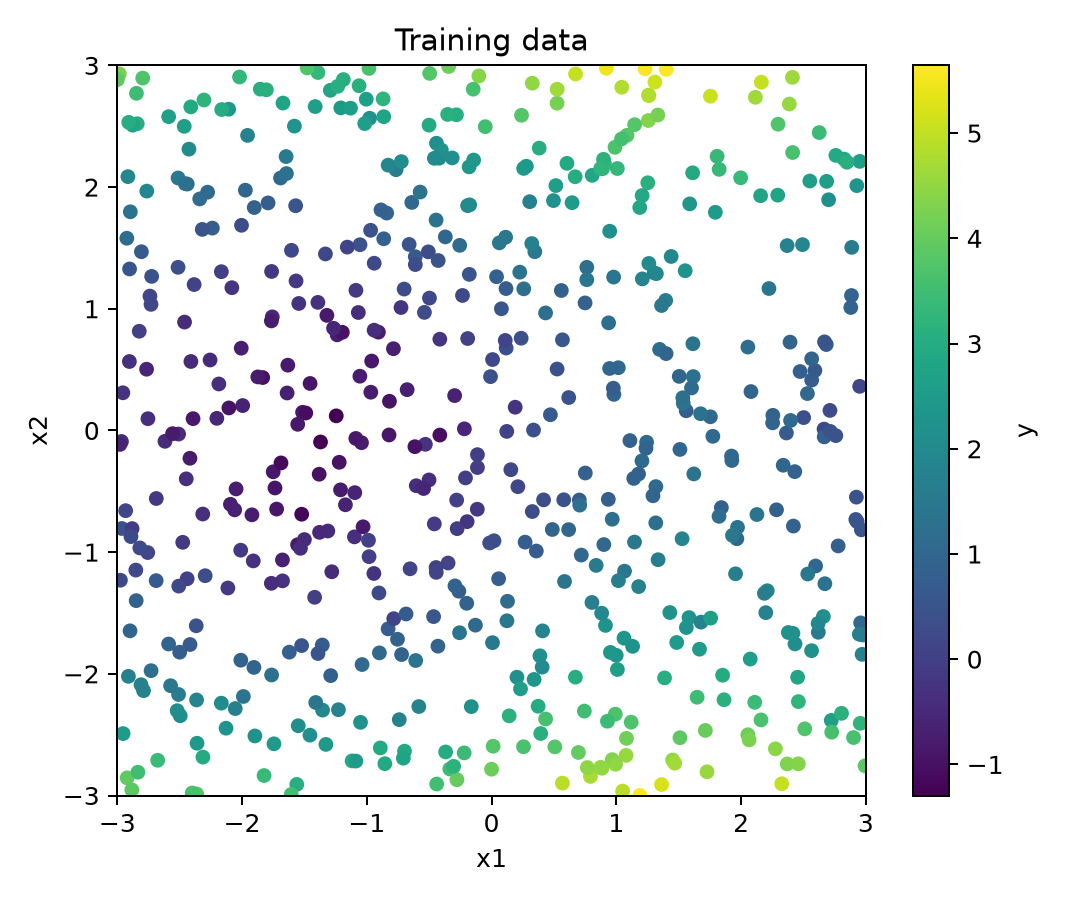

In [3]:
# Use the same color limits for the data and both fitted functions.
low = y_train.min()
high = y_train.max()

plt.figure(figsize=(6, 5))
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=24,
            cmap="viridis", vmin=low, vmax=high)
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Training data")
plt.colorbar(label="y")
plt.tight_layout()
plt.savefig("training_data.png", dpi=180)
plt.close()


from IPython.display import Image, display
display(Image(filename="training_data.png"))


## (b) RKS with ridge regression

I generate random sine and cosine features as specified in the question:

$$\phi_j^{\sin}(x)=\sin(w_j^\top x+b_j),\qquad
\phi_j^{\cos}(x)=\cos(w_j^\top x+b_j).$$

I fit a ridge regression on these features. Its objective is the sum of squared training errors plus $\lambda\|\beta\|_2^2$, with an unpenalized intercept. I vary the **total number of random features $D=2h$** and keep $\sigma=1$ and $\lambda=0.001$ fixed. The random seed is 42.

| D | Training MSE | Validation MSE |
|---|---:|---:|
| 20 | 0.035597 | 0.036619 |
| 50 | 0.032011 | 0.036996 |
| 100 | 0.031138 | 0.037911 |
| 200 | 0.030011 | 0.038918 |
| 400 | 0.029201 | 0.044044 |
| 800 | 0.028942 | 0.044198 |

The lowest validation MSE is obtained at **$D=20$**, corresponding to **$h=10$ sine/cosine pairs**. Training MSE decreases as more features are added, but validation MSE increases. In this sweep, more features fit the training data more closely without improving generalization.


In [4]:
class RKS:
    def __init__(self, D, sigma=1.0, alpha=0.001):
        h = D // 2
        rng = np.random.default_rng(42)
        self.w = rng.normal(size=(h, 2)) / sigma
        self.b = rng.uniform(0, 2 * np.pi, size=h)
        self.linear = Ridge(alpha=alpha)

    def features(self, x):
        a = x @ self.w.T + self.b
        return np.column_stack([np.sin(a), np.cos(a)])

    def fit(self, x, y):
        self.linear.fit(self.features(x), y)
        return self

    def predict(self, x):
        return self.linear.predict(self.features(x))


rows = []
for D in [20, 50, 100, 200, 400, 800]:
    model = RKS(D).fit(x_train, y_train)
    rows.append({
        "D": D,
        "Training MSE": mean_squared_error(y_train, model.predict(x_train)),
        "Validation MSE": mean_squared_error(y_val, model.predict(x_val))
    })

rks_results = pd.DataFrame(rows)
best_D = int(rks_results.loc[rks_results["Validation MSE"].idxmin(), "D"])
print("RKS sweep:")
print(rks_results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("Best D:", best_D)
rks_results.to_csv("rks_sweep.csv", index=False)



RKS sweep:
  D  Training MSE  Validation MSE
 20      0.035597        0.036619
 50      0.032011        0.036996
100      0.031138        0.037911
200      0.030011        0.038918
400      0.029201        0.044044
800      0.028942        0.044198
Best D: 20


### RKS sweep plots

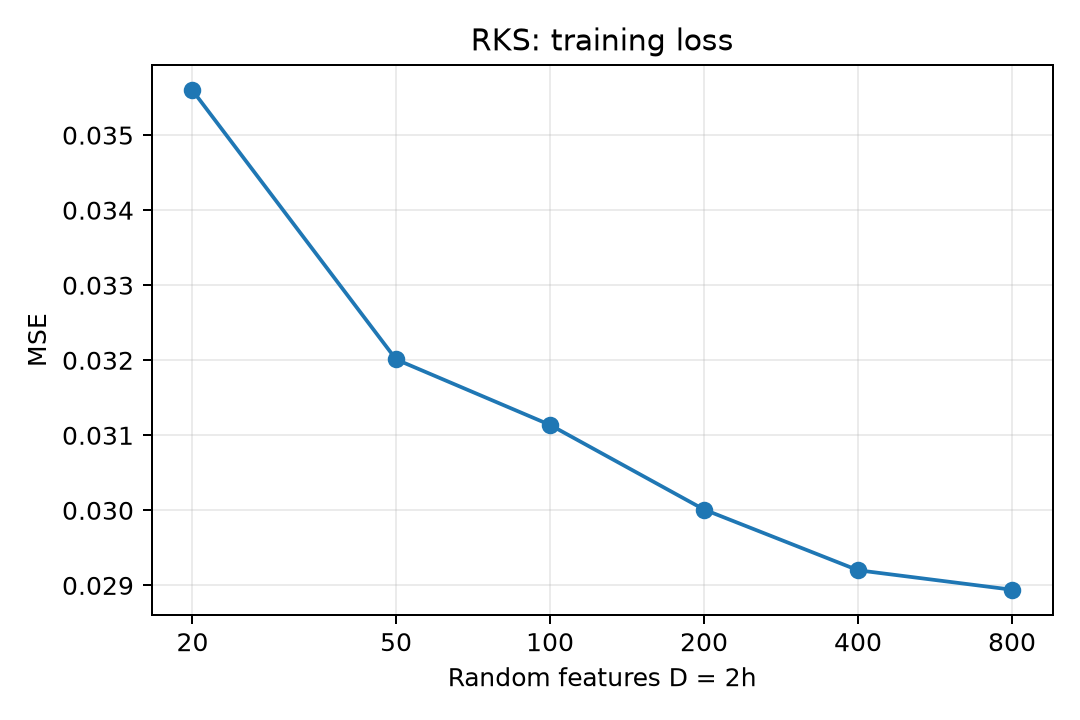

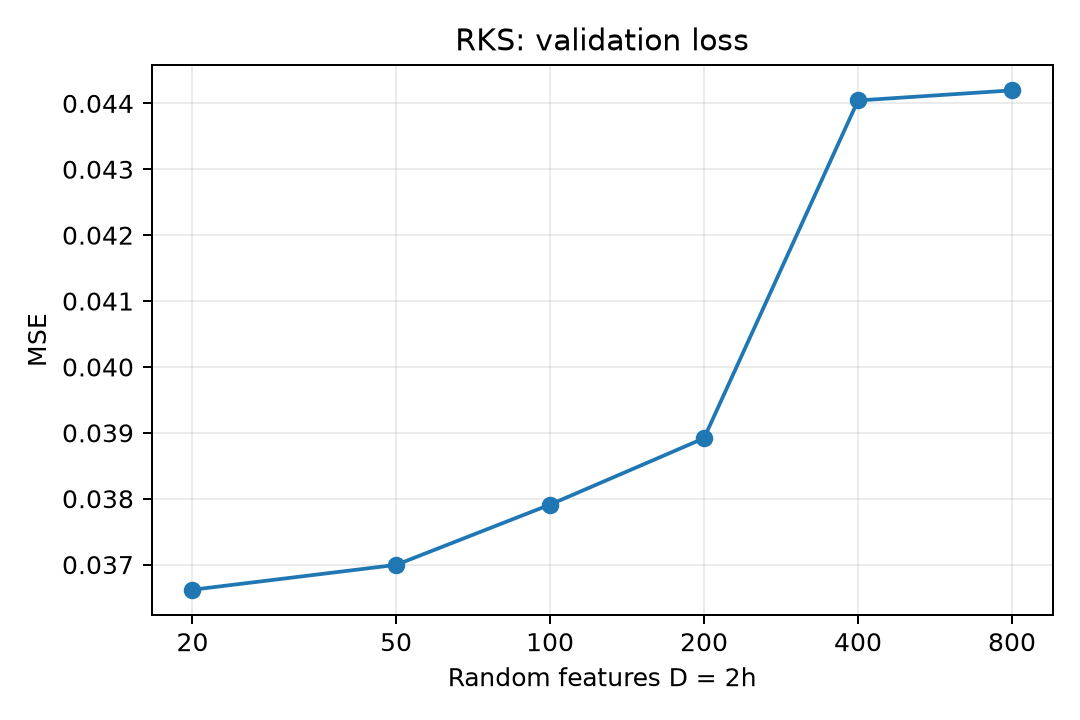

In [5]:
def plot_loss(values, losses, xlabel, title, filename):
    plt.figure(figsize=(6, 4))
    plt.plot(values, losses, "o-")
    plt.xscale("log", base=2)
    plt.xticks(values, [str(v) for v in values])
    plt.xlabel(xlabel)
    plt.ylabel("MSE")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(filename, dpi=180)
    plt.close()


plot_loss(rks_results["D"], rks_results["Training MSE"],
          "Random features D = 2h", "RKS: training loss", "rks_train_loss.png")
plot_loss(rks_results["D"], rks_results["Validation MSE"],
          "Random features D = 2h", "RKS: validation loss", "rks_val_loss.png")


from IPython.display import Image, display
display(Image(filename="rks_train_loss.png"))
display(Image(filename="rks_val_loss.png"))


## (c) One-hidden-layer MLP

I use a network with architecture **2 → width → 1**, with ReLU in the hidden layer. I vary only the hidden-layer width and keep the remaining settings fixed: Adam, learning rate **0.01**, **2,000 epochs**, and full-batch training using all 600 training points. The loss is MSE, and the random seed is 42.

| Width | Training MSE | Validation MSE |
|---|---:|---:|
| 8 | 0.048848 | 0.054602 |
| 16 | 0.034238 | 0.042560 |
| 32 | 0.031933 | 0.040968 |
| 64 | 0.030914 | 0.041156 |
| 128 | 0.028487 | 0.039241 |
| 256 | 0.026848 | 0.039203 |

I select **width 256**, which gives the lowest validation MSE among the tested widths. Widths 128 and 256 perform very similarly. Increasing width generally reduces training error, but the improvement in validation error becomes much smaller.


In [6]:
class MLP(nn.Module):
    def __init__(self, size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, size),
            nn.ReLU(),
            nn.Linear(size, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


x_train_t = torch.tensor(x_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)


def fit_mlp(size):
    torch.manual_seed(42)
    model = MLP(size)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    loss_fn = nn.MSELoss()

    # The dataset is small, so each update uses all 600 training examples.
    # The epoch count is fixed across all widths.
    model.train()
    for epoch in range(2000):
        optimizer.zero_grad()
        pred = model(x_train_t)
        loss = loss_fn(pred, y_train_t)
        loss.backward()
        optimizer.step()

    model.eval()
    return model


def predict_mlp(model, x):
    with torch.no_grad():
        return model(torch.tensor(x, dtype=torch.float32)).numpy()


rows = []
for size in [8, 16, 32, 64, 128, 256]:
    model = fit_mlp(size)
    rows.append({
        "Width": size,
        "Training MSE": mean_squared_error(y_train, predict_mlp(model, x_train)),
        "Validation MSE": mean_squared_error(y_val, predict_mlp(model, x_val))
    })
    print(f"Width {size}: validation MSE = {rows[-1]['Validation MSE']:.6f}")

mlp_results = pd.DataFrame(rows)
best_size = int(mlp_results.loc[mlp_results["Validation MSE"].idxmin(), "Width"])
print("MLP sweep:")
print(mlp_results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("Best width:", best_size)
mlp_results.to_csv("mlp_sweep.csv", index=False)



Width 8: validation MSE = 0.054571
Width 16: validation MSE = 0.042542
Width 32: validation MSE = 0.040981
Width 64: validation MSE = 0.041227
Width 128: validation MSE = 0.039876
Width 256: validation MSE = 0.044013
MLP sweep:
 Width  Training MSE  Validation MSE
     8      0.048805        0.054571
    16      0.034238        0.042542
    32      0.031934        0.040981
    64      0.030916        0.041227
   128      0.028455        0.039876
   256      0.030438        0.044013
Best width: 128


### MLP sweep plots

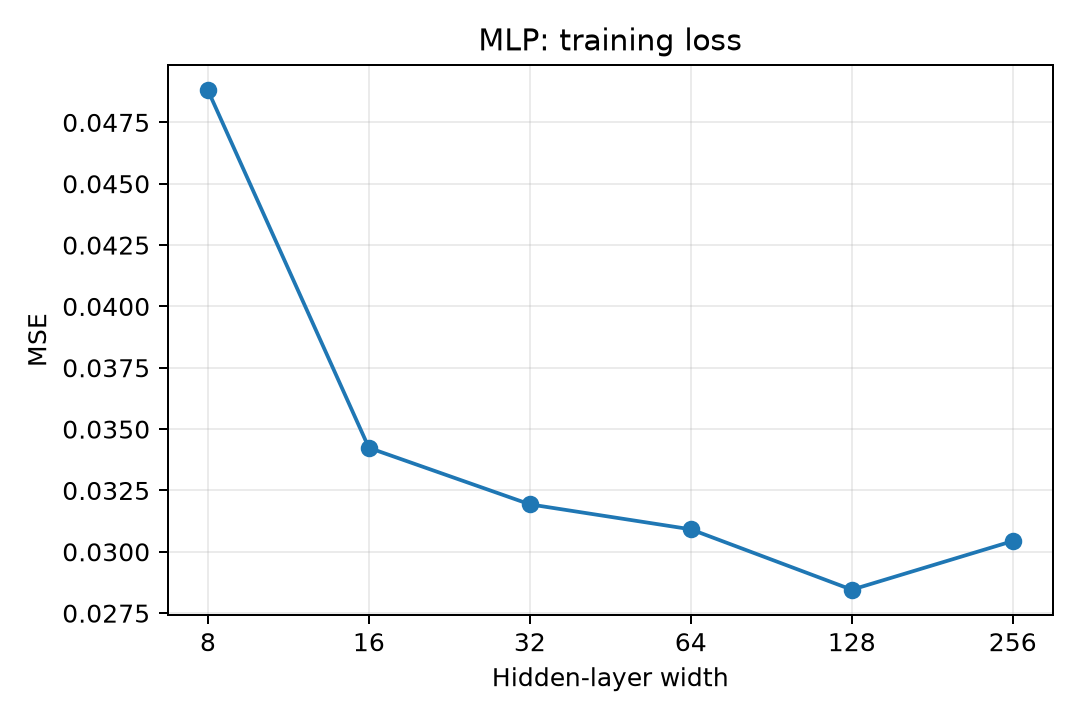

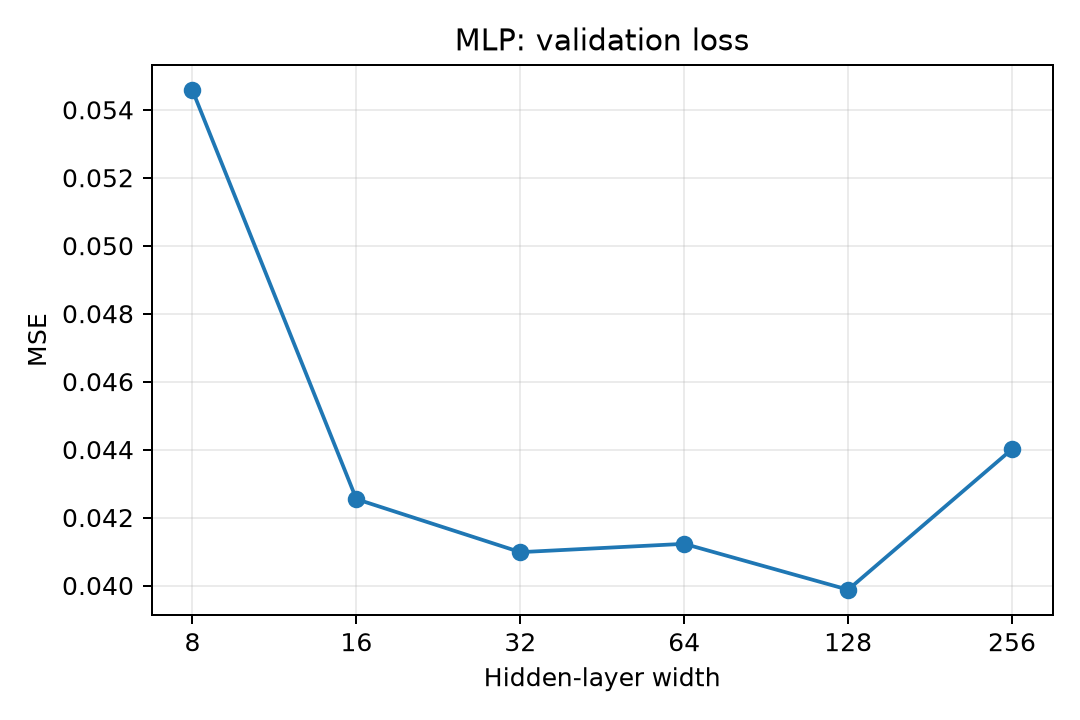

In [7]:
plot_loss(mlp_results["Width"], mlp_results["Training MSE"],
          "Hidden-layer width", "MLP: training loss", "mlp_train_loss.png")
plot_loss(mlp_results["Width"], mlp_results["Validation MSE"],
          "Hidden-layer width", "MLP: validation loss", "mlp_val_loss.png")


from IPython.display import Image, display
display(Image(filename="mlp_train_loss.png"))
display(Image(filename="mlp_val_loss.png"))


## (d) Comparison, predictions, and fitted functions

I refit both selected models on the training set using the same settings and seeds, keeping the validation set separate.

| Model | Training MSE | Validation MSE |
|---|---:|---:|
| RKS | 0.035597 | 0.036619 |
| MLP | 0.026848 | 0.039203 |

**RKS has the lower validation MSE in this experiment.** Its smooth random features provide a suitable representation of the pattern. The MLP has lower training MSE but slightly higher validation MSE, suggesting that the closer training fit does not translate into better validation performance. This comparison concerns the tested configurations rather than all possible RKS and MLP models.

Both fitted maps reproduce the low region near $x_1\approx-1.5$, $x_2\approx0$, and the higher values toward the top and bottom of the input space. RKS produces smooth contours, while the ReLU MLP has more angular contours because its function is piecewise linear.

The test set has no labels, so test MSE cannot be calculated. I save predictions as **`rks_test_predictions.csv`** and **`mlp_test_predictions.csv`**. Each file contains **200 numeric rows and one column, without a header or index**, in exactly the original order of `test.csv`.


### Refit the selected models and compare

In [8]:
# Refit on the training set only, keeping validation separate.
# Reuse the same seeds and training settings as in the sweeps.
rks = RKS(best_D).fit(x_train, y_train)
mlp = fit_mlp(best_size)

results = pd.DataFrame([
    {"Model": "RKS", "Training MSE": mean_squared_error(y_train, rks.predict(x_train)),
     "Validation MSE": mean_squared_error(y_val, rks.predict(x_val))},
    {"Model": "MLP", "Training MSE": mean_squared_error(y_train, predict_mlp(mlp, x_train)),
     "Validation MSE": mean_squared_error(y_val, predict_mlp(mlp, x_val))}
])
print("Refitted models:")
print(results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
results.to_csv("results.csv", index=False)



Refitted models:
Model  Training MSE  Validation MSE
  RKS      0.035597        0.036619
  MLP      0.028455        0.039876


### Save test predictions in their original row order

In [9]:
rks_pred = rks.predict(x_test)
mlp_pred = predict_mlp(mlp, x_test)

# Exactly 200 numeric rows per file: one column, no header or index.
np.savetxt("rks_test_predictions.csv", rks_pred, delimiter=",")
np.savetxt("mlp_test_predictions.csv", mlp_pred, delimiter=",")
print("Saved predictions:", len(rks_pred), "rows for each model.")



Saved predictions: 200 rows for each model.


### Visualize the fitted functions

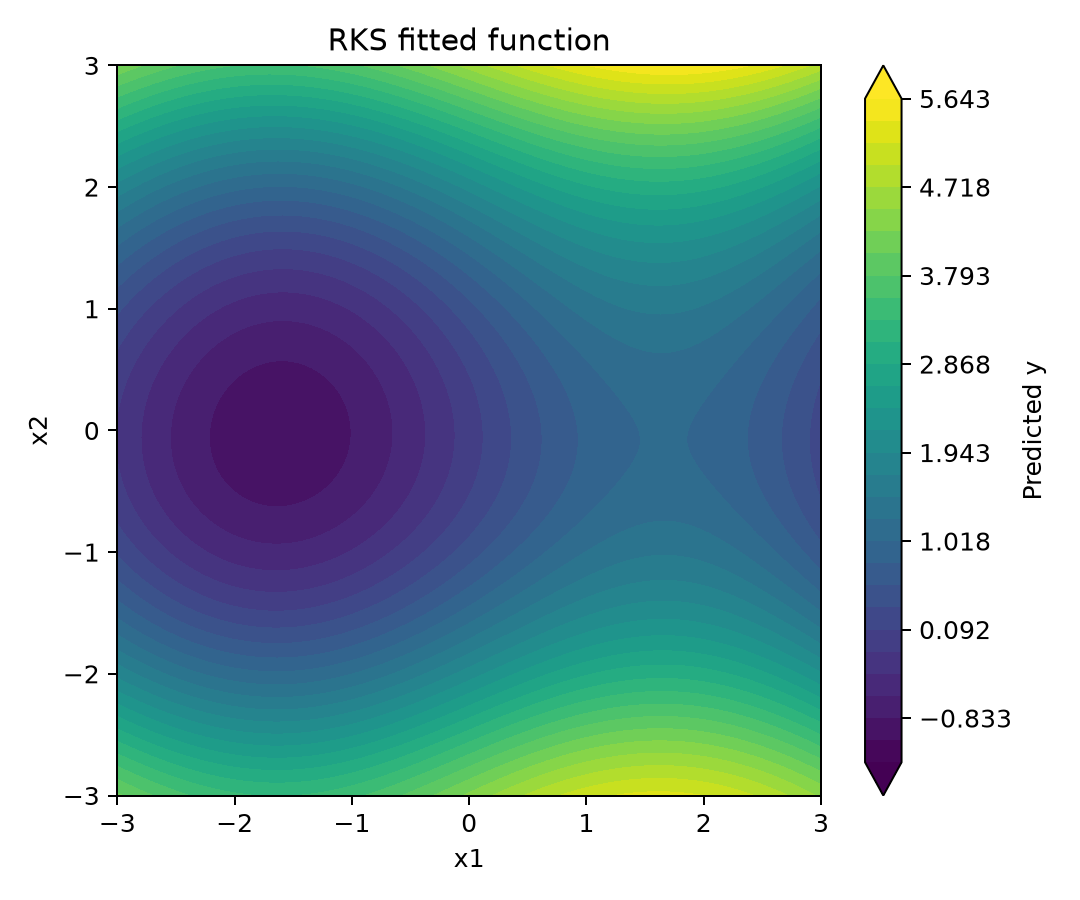

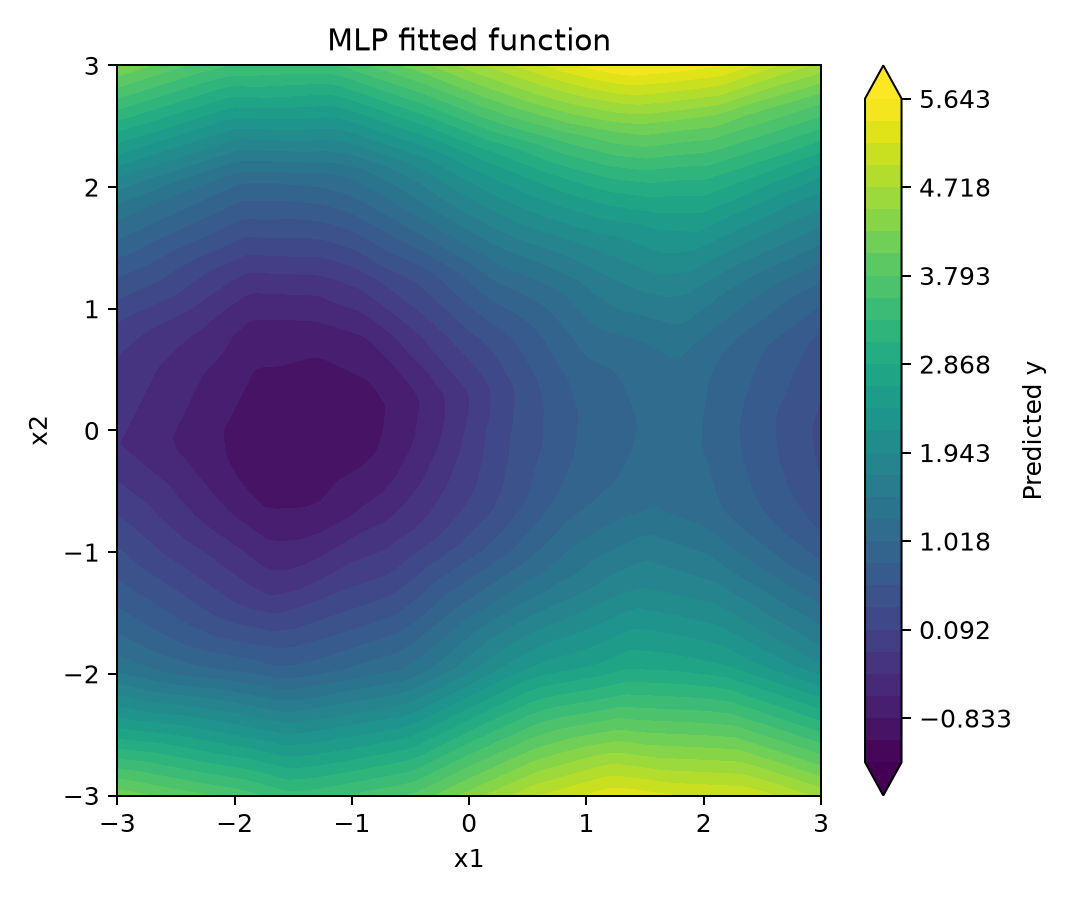

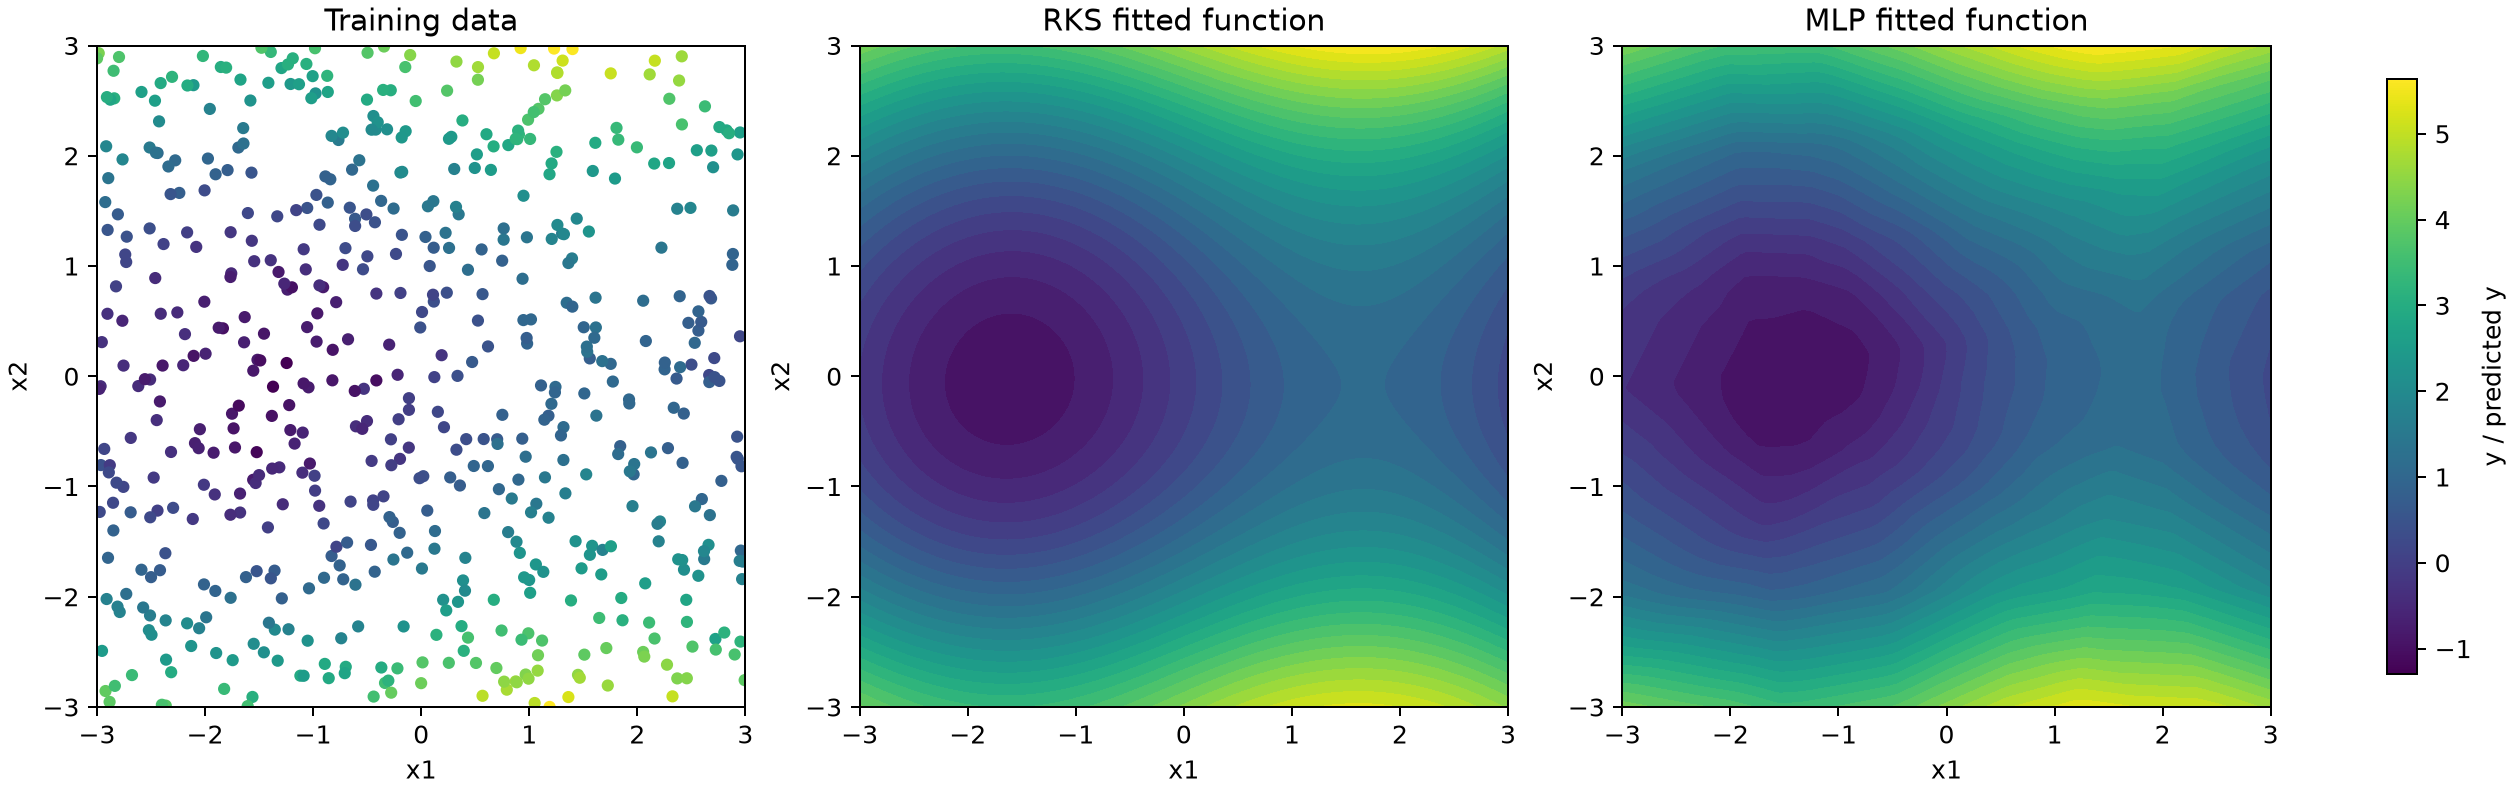

In [10]:
xs = np.linspace(-3, 3, 150)
x1, x2 = np.meshgrid(xs, xs)
grid = np.column_stack([x1.ravel(), x2.ravel()])

z_rks = rks.predict(grid).reshape(x1.shape)
z_mlp = predict_mlp(mlp, grid).reshape(x1.shape)

# Color-filled maps use common levels and color limits for comparison.
levels = np.linspace(low, high, 31)
for name, z in [("RKS", z_rks), ("MLP", z_mlp)]:
    plt.figure(figsize=(6, 5))
    plt.contourf(x1, x2, z, levels=levels, cmap="viridis", extend="both")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(name + " fitted function")
    plt.colorbar(label="Predicted y")
    plt.tight_layout()
    plt.savefig(name.lower() + "_surface.png", dpi=180)
    plt.close()

# Put the observed data and fitted maps side by side as well.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
axes[0].scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=15,
                cmap="viridis", vmin=low, vmax=high)
axes[0].set_title("Training data")
for ax, name, z in zip(axes[1:], ["RKS", "MLP"], [z_rks, z_mlp]):
    ax.contourf(x1, x2, z, levels=levels, cmap="viridis", extend="both")
    ax.set_title(name + " fitted function")
for ax in axes:
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(low, high), cmap="viridis"),
             ax=axes, label="y / predicted y", shrink=0.9)
fig.savefig("surface_comparison.png", dpi=180)
plt.close(fig)

from IPython.display import Image, display
display(Image(filename="rks_surface.png"))
display(Image(filename="mlp_surface.png"))
display(Image(filename="surface_comparison.png"))
